kode pembuatan model kNN 

In [1]:
#Import Library 
import numpy as np 
from scipy import stats 
from typing import Dict, Any 
from abc import ABC,abstractmethod 
from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes, load_breast_cancer 
from sklearn.model_selection import StratifiedKFold, cross_validate 
from sklearn.metrics import (mean_squared_error,
                            mean_absolute_error,
                            accuracy_score,
                            precision_score,
                            recall_score,
                            f1_score,
                            make_scorer)
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier 
from sklearn.preprocessing import StandardScaler 
from sklearn.pipeline import Pipeline 
 
#Generating kNN Class 
class KNN(BaseEstimator,ABC): 
    """ 
    Base class for KNN implementations 
    """ 
     
    def __init__(self, K : int = 3, metric : str = 'minkowski', p : int = 2) -> None: 
        """ 
        Initializer function. Ensure that input parameters are compatiable. 
        Inputs: 
            K      -> integer specifying number of neighbours to consider 
            metric -> string to indicate the distance metric to use (valid entries are 'minkowski' or 'cosine') 
            p      -> order of the minkowski metric (valid only when distance == 'minkowski') 
        """ 
        # check distance is a valid entry 
        valid_distance = ['minkowski','cosine'] 
        if metric not in valid_distance: 
            msg = "Entered value for metric is not valid. Pick one of {}".format(valid_distance) 
            raise ValueError(msg) 

        # check minkowski p parameter 
        if (metric == 'minkowski') and (p <= 0): 
            msg = "Entered value for p is not valid. For metric = 'minkowski', p >= 1" 
            raise ValueError(msg) 
        # store/initialise input parameters 
        self.K       = K 
        self.metric  = metric 
        self.p       = p 
        self.X_train = np.array([]) 
        self.y_train = np.array([]) 
         
    def __del__(self) -> None: 
        """ 
        Destructor function.  
        """ 
        del self.K 
        del self.metric 
        del self.p 
        del self.X_train 
        del self.y_train 
       
    def __minkowski(self, x : np.array) -> np.array: 
        """ 
        Private function to compute the minkowski distance between point x and the training data X 
        Inputs: 
            x -> numpy data point of predictors to consider 
        Outputs: 
            np.array -> numpy array of the computed distances 
        """ 
        return np.power(np.sum(np.power(np.abs(self.X_train - x),self.p),axis=1),1/self.p) 
     
    def __cosine(self, x : np.array) -> np.array: 
        """ 
        Private function to compute the cosine distance between point x and the training data X 
        Inputs: 
            x -> numpy data point of predictors to consider 
        Outputs: 
            np.array -> numpy array of the computed distances 
        """ 
        return (1 - (np.dot(self.X_train,x)/(np.linalg.norm(x)*np.linalg.norm(self.X_train,axis=1)))) 
     
    def __distances(self, X : np.array) -> np.array: 
        """ 
        Private function to compute distances to each point x in X[x,:] 
        Inputs: 
            X -> numpy array of points [x] 
        Outputs: 
            D -> numpy array containing distances from x to all points in the training set. 
        """ 
        # cover distance calculation 
        if self.metric == 'minkowski': 
            D = np.apply_along_axis(self.__minkowski,1,X) 
        elif self.metric == 'cosine': 
            D = np.apply_along_axis(self.__cosine,1,X) 
        # return computed distances 
        return D 
     
    @abstractmethod 
    def _generate_predictions(self, idx_neighbours : np.array) -> np.array: 
        """ 
        Protected function to compute predictions from the K nearest neighbours 
        """ 
        pass 
         
    def fit(self, X : np.array, y : np.array) -> None: 
        """ 
        Public training function for the class. It is assummed input X has been normalised. 
        Inputs: 
            X -> numpy array containing the predictor features 
            y -> numpy array containing the labels associated with each value in X 
        """ 
        # store training data 
        self.X_train = np.copy(X) 
        self.y_train = np.copy(y) 
        return self

    def __sklearn_is_fitted__(self) -> bool:
        return (self.X_train.size != 0) and (self.y_train.size != 0)
         
    def predict(self, X : np.array) -> np.array: 
        """ 
        Public prediction function for the class.  
        It is assummed input X has been normalised in the same fashion as the input to the training function 
        Inputs: 
            X -> numpy array containing the predictor features 
        Outputs: 
           y_pred -> numpy array containing the predicted labels 
        """ 
        # ensure we have already trained the instance 
        if (self.X_train.size == 0) or (self.y_train.size == 0): 
            raise Exception('Model is not trained. Call fit before calling predict.') 
        # compute distances 
        D = self.__distances(X) 
        # obtain indices for the K nearest neighbours 
        idx_neighbours = D.argsort()[:,:self.K] 
        # compute predictions 
        y_pred = self._generate_predictions(idx_neighbours) 
        # return results 
        return y_pred 
     
    def get_params(self, deep : bool = False) -> Dict: 
        """ 
        Public function to return model parameters 
        Inputs: 
            deep -> boolean input parameter 
        Outputs: 
            Dict -> dictionary of stored class input parameters 
        """ 
        return {'K':self.K, 
                'metric':self.metric, 
                'p':self.p} 
 
#Generating kNN Classifier 
class KNNClassifier(KNN): 
    """ 
    Class for KNN classifiction implementation 
    """ 
     
    def __init__(self, K : int = 3, metric : str = 'minkowski', p : int = 2) -> None: 
        """ 
        Initializer function. Ensure that input parameters are compatiable. 
        Inputs: 
            K       -> integer specifying number of neighbours to consider 
            metric  -> string to indicate the distance metric to use (valid entries are 'minkowski' or 'cosine') 
            p       -> order of the minkowski metric (valid only when distance == 'minkowski') 
        """ 
        # call base class initialiser 
        super().__init__(K,metric,p) 
         
    def _generate_predictions(self, idx_neighbours : np.array) -> np.array: 
        """ 
        Protected function to compute predictions from the K nearest neighbours 
        Inputs: 
            idx_neighbours -> indices of nearest neighbours 
        Outputs: 
            y_pred -> numpy array of prediction results 
        """         
        # compute the mode label for each submitted sample 
        y_pred = stats.mode(self.y_train[idx_neighbours],axis=1).mode.flatten()    
        # return result 
        return y_pred 
 
#Implementing and Evaluation 
#load classification dataset 
data = load_breast_cancer()
X    = data.data 
y    = data.target 
 
#properly format labels 
y = np.where(y==0,-1,1) 
 
#define the scoring metrics 
scoring_metrics = {'accuracy' : make_scorer(accuracy_score),  
                   'precision': make_scorer(precision_score), 
                   'recall'   : make_scorer(recall_score), 
                   'f1'       : make_scorer(f1_score)} 
 
## define a helper function for our analysis ## 
def cv_classifier_analysis(pipe : Any,  
                           X : np.array,  
                           y : np.array,  
                           k : int,  
                           scoring_metrics : Dict, 
                           metric : str) -> None: 
    """ 
    Function to carry out cross-validation analysis for input KNN classifier 
    Inputs: 
        pipe            -> input pipeline containing preprocessing and KNN classifier 
        X               -> numpy array of predictors 
        y               -> numpy array of labels 
        k               -> integer value for number of nearest neighbours to consider 
        scoring_metrics -> dictionary of scoring metrics to consider  
        metric          -> string indicating distance metric used 
    """ 
    # print hyperparameter configuration 
    print('RESULTS FOR K = {0}, {1}'.format(k,metric)) 
    # run cross validation 
    dcScores = cross_validate(pipe,X,y,cv=StratifiedKFold(10),scoring=scoring_metrics) 
    # report results 
    print('Mean Accuracy: %.2f' % np.mean(dcScores['test_accuracy'])) 
    print('Mean Precision: %.2f' % np.mean(dcScores['test_precision'])) 
    print('Mean Recall: %.2f' % np.mean(dcScores['test_recall'])) 
    print('Mean F1: %.2f' % np.mean(dcScores['test_f1'])) 
 
#perform cross-validation for a range of model hyperparameters for the Custom model 
K = [3,6,9] 
for k in K: 
    # define the pipeline for manhatten distance 
    p_manhat = Pipeline([('scaler', StandardScaler()), ('knn', KNNClassifier(k, 
metric = 'minkowski', p = 1))]) 
    # define the pipeline for euclidean distance 
    p_euclid = Pipeline([('scaler', StandardScaler()), ('knn', KNNClassifier(k, 
metric = 'minkowski', p = 2))]) 
    # define the pipeline for cosine distance 
    p_cosine = Pipeline([('scaler', StandardScaler()), ('knn', KNNClassifier(k, 
metric = 'cosine'))]) 
    # cross validate for p_manhat
cv_classifier_analysis(p_manhat, X, y, k, scoring_metrics, 'MANHATTEN DISTANCE') 
# cross validate for p_euclid 
cv_classifier_analysis(p_euclid, X, y, k, scoring_metrics, 'EUCLIDEAN DISTANCE') 
# cross validate for p_cosine 
cv_classifier_analysis(p_cosine, X, y, k, scoring_metrics, 'COSINE DISTANCE')

RESULTS FOR K = 9, MANHATTEN DISTANCE
Mean Accuracy: 0.96
Mean Precision: 0.96
Mean Recall: 0.99
Mean F1: 0.97
RESULTS FOR K = 9, EUCLIDEAN DISTANCE
Mean Accuracy: 0.97
Mean Precision: 0.96
Mean Recall: 0.99
Mean F1: 0.97
RESULTS FOR K = 9, COSINE DISTANCE
Mean Accuracy: 0.96
Mean Precision: 0.96
Mean Recall: 0.98
Mean F1: 0.97


kode pembuatan model SVM 

First five rows and col values 
X1 : 
 [[2.51526543 1.11143935]
 [1.8155981  1.11969719]
 [2.69637316 0.62563218]
 [1.67280531 0.65930057]
 [1.89593761 5.18540259]]  
 y1 :
 [ 1  1  1  1 -1]


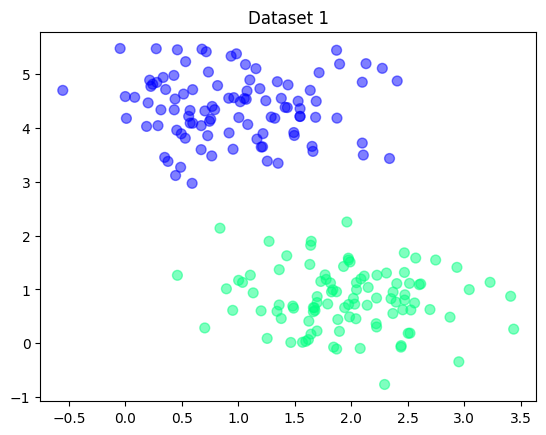

First five rows and col values 
X2 : 
 [[ 0.24251072  0.9546847 ]
 [-0.40883697  0.87436084]
 [ 0.14075484  0.99103948]
 [-0.99115853  0.05635   ]
 [-0.84577654  0.50085188]]  
 y2 :
 [ 1  1  1  1 -1]


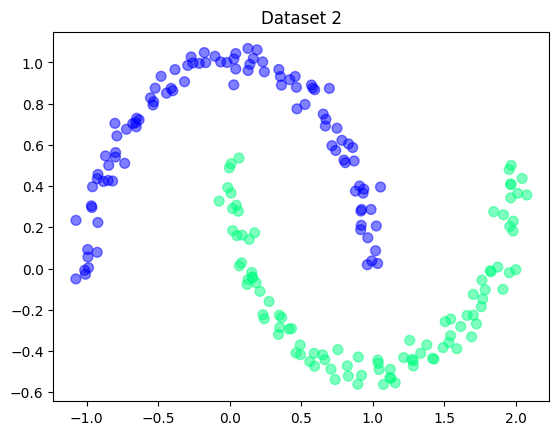

First five rows and col values 
X1 : 
 [[-1.03907162 -0.13255604]
 [-0.75250467  0.68319563]
 [ 0.91388697  0.3540641 ]
 [ 0.45333249  0.23521576]
 [-0.4441874   0.14999163]]  
 y3 :
 [ 1  1  1  1 -1]


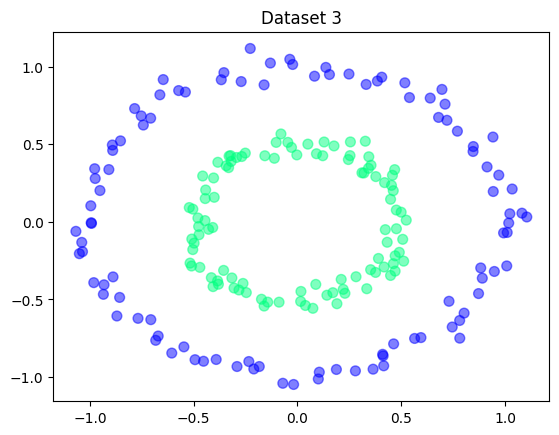

For dataset 1, score: 1.0


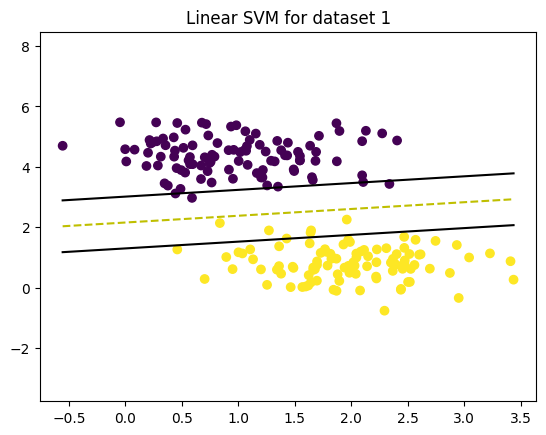

For dataset 2, score: 0.85


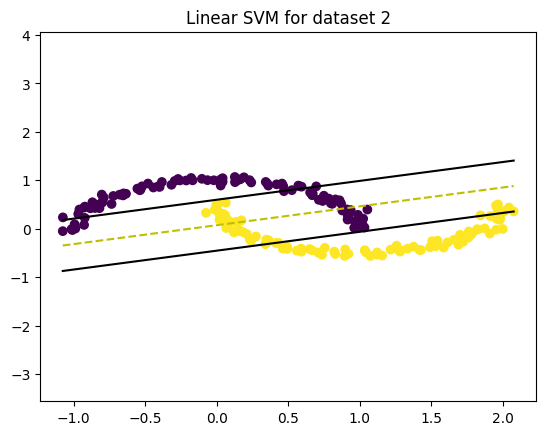

For dataset 3, score: 0.505


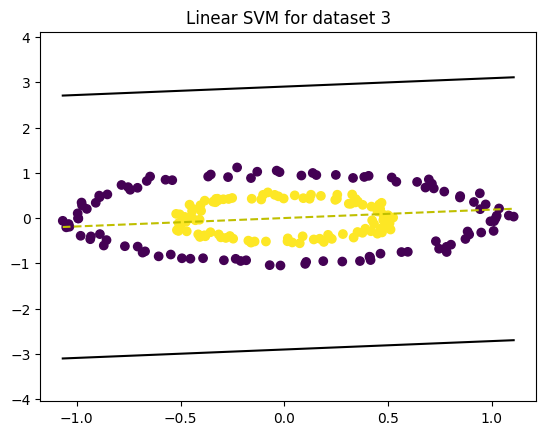

In [2]:
#Creating Dataset 
import numpy as np 
import pandas as pd 
import random 
import matplotlib.pyplot as plt 
from sklearn.datasets import make_blobs, make_moons, make_circles 
from sklearn.metrics import mean_squared_error 
from sklearn.svm import SVC 
from sklearn.model_selection import train_test_split 
from sklearn.metrics import accuracy_score

#X1 Using make_blobs 
X1, y1 = make_blobs(n_samples=200, centers=2,random_state=0, cluster_std=0.60) 
y1 = np.where(y1 <= 0, -1, 1) 
print("First five rows and col values \nX1 : \n",X1[:5], " \n y1 :\n",y1[:5]) 
plt.scatter(X1[:, 0], X1[:, 1], c=y1, s=50, cmap='winter', alpha=.5) 
plt.title("Dataset 1") 
plt.show() 
 
#X2 Using make_moons 
X2, y2 = make_moons(n_samples=200, noise=.05) 
y2 = np.where(y2 <= 0, -1, 1) 
print("First five rows and col values \nX2 : \n",X2[:5], " \n y2 :\n",y1[:5]) 
plt.scatter(X2[:, 0], X2[:, 1], c=y2, s=50, cmap='winter', alpha=.5) 
plt.title("Dataset 2") 
plt.show() 
 
#X3 Using make_circles 
X3, y3 = noisy_circles = make_circles(n_samples=200, factor=.5, noise=.05) 
y3 = np.where(y3 <= 0, -1, 1) 
print("First five rows and col values \nX1 : \n",X3[:5], " \n y3 :\n",y1[:5]) 
plt.scatter(X3[:, 0], X3[:, 1], c=y3, s=50, cmap='winter', alpha=.5) 
plt.title("Dataset 3") 
plt.show() 
 
#Generating SVM soft Margin 
class SVM_soft_margin: 
 
    def __init__(self, alpha = 0.001, lambda_ = 0.01, n_iterations = 1000): 
        self.alpha = alpha # learning rate 
        self.lambda_ = lambda_ # tradeoff 
        self.n_iterations = n_iterations # number of iterations 
        self.w = None # weights or slopes 
        self.b = None # intercept 
 
 
    def fit(self, X, y): 
         
        n_samples, n_features = X.shape         
        self.w = np.zeros(n_features) # initalizing with 0 
        self.b = 0 # initializewith 0 
         
        for iteration in range(self.n_iterations): 
            for i, Xi in enumerate(X): 
                # yixiw-b≥1 
                if y[i] * (np.dot(Xi, self.w) - self.b) >= 1 :  
                    self.w -= self.alpha * (2 * self.lambda_ * self.w) # w = w + α* (2λw - yixi) 
                else: 
                    self.w -= self.alpha * (2 * self.lambda_ * self.w - np.dot(Xi, y[i])) # w = w + α* (2λw - yixi) 
                    self.b -= self.alpha * y[i] # b = b - α* (yi) 
        return self.w, self.b 
 
 
    def predict(self, X): 
            pred = np.dot(X, self.w) - self.b  
            result = [1 if val > 0 else -1 for val in pred] # returning in the form of -1 and 1 
            return result 
 
def get_hyperplane(x, w, b, offset): 
        return (-w[0] * x + b + offset) / w[1] 
 
def plot_svm(X, y, w, b, title ='Plot for linear SVM'):     
 
    fig = plt.figure() 
    ax = fig.add_subplot(1,1,1) 
    plt.scatter(X[:,0], X[:,1], marker='o',c=y) 
 
    x0_1 = np.amin(X[:,0]) 
    x0_2 = np.amax(X[:,0]) 
 
    x1_1 = get_hyperplane(x0_1, w, b, 0) 
    x1_2 = get_hyperplane(x0_2, w, b, 0) 
 
    x1_1_m = get_hyperplane(x0_1, w, b, -1) 
    x1_2_m = get_hyperplane(x0_2, w, b, -1) 
 
    x1_1_p = get_hyperplane(x0_1, w, b, 1) 
    x1_2_p = get_hyperplane(x0_2, w, b, 1) 
 
    ax.plot([x0_1, x0_2],[x1_1, x1_2], 'y--') 
    ax.plot([x0_1, x0_2],[x1_1_m, x1_2_m], 'k') 
    ax.plot([x0_1, x0_2],[x1_1_p, x1_2_p], 'k') 
 
    x1_min = np.amin(X[:,1]) 
    x1_max = np.amax(X[:,1]) 
    ax.set_ylim([x1_min-3,x1_max+3]) 
     
    plt.title(title) 
    plt.show() 
 
#Implementing into each Datasets 
svm1 = SVM_soft_margin() 
w1,b1 = svm1.fit(X1,y1) 
print("For dataset 1, score:" ,accuracy_score(svm1.predict(X1),y1)) 
plot_svm(X1, y1, w1, b1, title= 'Linear SVM for dataset 1') 
 
svm2 = SVM_soft_margin() 
w2,b2 = svm2.fit(X2,y2) 
print("For dataset 2, score:" ,accuracy_score(svm2.predict(X2),y2)) 
plot_svm(X2, y2, w2, b2, title= 'Linear SVM for dataset 2') 
 
svm3 = SVM_soft_margin() 
w3,b3 = svm3.fit(X3,y3) 
print("For dataset 3, score:" ,accuracy_score(svm3.predict(X3),y3)) 
plot_svm(X3, y3, w3, b3, title= 'Linear SVM for dataset 3') 


In [4]:
import sys
!{sys.executable} -m pip install kagglehub

  Using cached kagglehub-1.0.2-py3-none-any.whl.metadata (40 kB)
  Using cached kagglesdk-0.1.37-py3-none-any.whl.metadata (13 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
Using cached kagglehub-1.0.2-py3-none-any.whl (70 kB)
Using cached kagglesdk-0.1.37-py3-none-any.whl (262 kB)
Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl (456 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

   ---------------------------------------- 0/4 [tqdm]
   ---------- ----------------------------- 1/4 [protobuf]
   ---------- ----------------------------- 1/4 [protobuf]
   ---------- ----------------------------- 1/4 [protobuf]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- -----------

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import os
import kagglehub

# unduh dataset dari Kaggle (pertama kali agak lama, berikutnya pakai cache)
path = kagglehub.dataset_download("taranvee/smart-home-dataset-with-weather-information")
print("Folder dataset:", path)
print(os.listdir(path))

df = pd.read_csv(os.path.join(path, 'HomeC.csv'), low_memory=False)
print(df.shape)
print(df['summary'].value_counts())

# fitur = parameter hasil pengukuran sensor cuaca
fitur = ['temperature', 'humidity', 'visibility', 'apparentTemperature', 'pressure',
         'windSpeed', 'cloudCover', 'windBearing', 'precipIntensity', 'dewPoint',
         'precipProbability']

data_cuaca = df[fitur + ['summary']].copy()
for kol in fitur:
    data_cuaca[kol] = pd.to_numeric(data_cuaca[kol], errors='coerce')  # ada isian teks 'cloudCover' di kolom cloudCover
data_cuaca = data_cuaca.dropna()
data_cuaca = data_cuaca.drop_duplicates()   # data cuaca berulang tiap menit dalam 1 jam
print('Jumlah data unik:', len(data_cuaca))

100%|██████████| 19.4M/19.4M [00:02<00:00, 9.76MB/s]

Extracting files...


Folder dataset: C:\Users\USER\.cache\kagglehub\datasets\taranvee\smart-home-dataset-with-weather-information\versions\1
['HomeC.csv']
(503911, 32)
summary
Clear                       376730
Partly Cloudy                62268
Light Rain                   27368
Drizzle                      10370
Overcast                      6041
Rain                          5169
Mostly Cloudy                 4548
Light Snow                    4323
Flurries                      1789
Breezy                        1561
Snow                          1152
Breezy and Partly Cloudy      1041
Foggy                          974
Rain and Breezy                174
Heavy Snow                     171
Flurries and Breezy            115
Breezy and Mostly Cloudy        58
Dry                             58
Name: count, dtype: int64
Jumlah data unik: 8759


In [6]:
def buat_kelas(s):
    if s == 'Clear':
        return 0          # cerah
    elif s in ['Partly Cloudy', 'Mostly Cloudy', 'Overcast']:
        return 1          # berawan
    else:
        return 2          # lainnya (hujan, gerimis, berangin, salju, dll.)

data_cuaca['kelas'] = data_cuaca['summary'].apply(buat_kelas)
nama_kelas = ['Cerah', 'Berawan', 'Lainnya']
print(data_cuaca['kelas'].value_counts().sort_index())

X_all = data_cuaca[fitur].values
y_all = data_cuaca['kelas'].values

# kNN buatan sendiri lambat untuk data besar, jadi diambil 3000 sampel (proporsi kelas tetap)
N_SAMPEL = 3000
if len(X_all) > N_SAMPEL:
    X_cuaca, _, y_cuaca, _ = train_test_split(X_all, y_all, train_size=N_SAMPEL,
                                              stratify=y_all, random_state=42)
else:
    X_cuaca, y_cuaca = X_all, y_all
print('Data yang dipakai:', X_cuaca.shape)

kelas
0    6548
1    1267
2     944
Name: count, dtype: int64
Data yang dipakai: (3000, 11)


In [7]:
# karena 3 kelas, precision/recall/f1 pakai average='macro'
scoring_cuaca = {'accuracy' : make_scorer(accuracy_score),
                 'precision': make_scorer(precision_score, average='macro', zero_division=0),
                 'recall'   : make_scorer(recall_score, average='macro', zero_division=0),
                 'f1'       : make_scorer(f1_score, average='macro', zero_division=0)}

K = [3,6,9]
for k in K:
    p_manhat = Pipeline([('scaler', StandardScaler()), ('knn', KNNClassifier(k, metric='minkowski', p=1))])
    p_euclid = Pipeline([('scaler', StandardScaler()), ('knn', KNNClassifier(k, metric='minkowski', p=2))])
    p_cosine = Pipeline([('scaler', StandardScaler()), ('knn', KNNClassifier(k, metric='cosine'))])
    cv_classifier_analysis(p_manhat, X_cuaca, y_cuaca, k, scoring_cuaca, 'MANHATTEN DISTANCE')
    cv_classifier_analysis(p_euclid, X_cuaca, y_cuaca, k, scoring_cuaca, 'EUCLIDEAN DISTANCE')
    cv_classifier_analysis(p_cosine, X_cuaca, y_cuaca, k, scoring_cuaca, 'COSINE DISTANCE')

RESULTS FOR K = 3, MANHATTEN DISTANCE
Mean Accuracy: 0.87
Mean Precision: 0.83
Mean Recall: 0.76
Mean F1: 0.79
RESULTS FOR K = 3, EUCLIDEAN DISTANCE
Mean Accuracy: 0.87
Mean Precision: 0.83
Mean Recall: 0.77
Mean F1: 0.80
RESULTS FOR K = 3, COSINE DISTANCE
Mean Accuracy: 0.88
Mean Precision: 0.84
Mean Recall: 0.78
Mean F1: 0.80
RESULTS FOR K = 6, MANHATTEN DISTANCE
Mean Accuracy: 0.87
Mean Precision: 0.85
Mean Recall: 0.71
Mean F1: 0.75
RESULTS FOR K = 6, EUCLIDEAN DISTANCE
Mean Accuracy: 0.87
Mean Precision: 0.84
Mean Recall: 0.71
Mean F1: 0.75
RESULTS FOR K = 6, COSINE DISTANCE
Mean Accuracy: 0.87
Mean Precision: 0.84
Mean Recall: 0.73
Mean F1: 0.76
RESULTS FOR K = 9, MANHATTEN DISTANCE
Mean Accuracy: 0.87
Mean Precision: 0.86
Mean Recall: 0.72
Mean F1: 0.77
RESULTS FOR K = 9, EUCLIDEAN DISTANCE
Mean Accuracy: 0.87
Mean Precision: 0.86
Mean Recall: 0.73
Mean F1: 0.77
RESULTS FOR K = 9, COSINE DISTANCE
Mean Accuracy: 0.88
Mean Precision: 0.85
Mean Recall: 0.75
Mean F1: 0.78


=== kNN ===
              precision    recall  f1-score   support

       Cerah       0.85      0.98      0.91       448
     Berawan       0.71      0.28      0.40        87
     Lainnya       0.98      0.71      0.82        65

    accuracy                           0.85       600
   macro avg       0.84      0.65      0.71       600
weighted avg       0.84      0.85      0.82       600



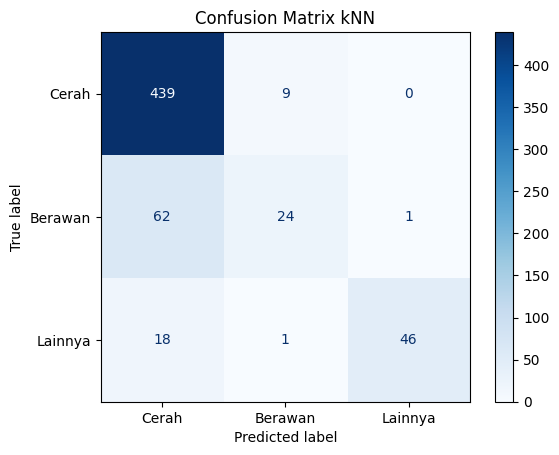

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X_cuaca, y_cuaca, test_size=0.2,
                                                    stratify=y_cuaca, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# ganti K dan metric sesuai kombinasi terbaik dari Cell 3.3
knn_cuaca = KNNClassifier(K=6, metric='minkowski', p=1)
knn_cuaca.fit(X_train_s, y_train)
y_pred_knn = knn_cuaca.predict(X_test_s)

print('=== kNN ===')
print(classification_report(y_test, y_pred_knn, target_names=nama_kelas, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_knn), display_labels=nama_kelas).plot(cmap='Blues')
plt.title('Confusion Matrix kNN')
plt.show()

=== SVM ===
              precision    recall  f1-score   support

       Cerah       0.81      1.00      0.90       448
     Berawan       0.00      0.00      0.00        87
     Lainnya       1.00      0.77      0.87        65

    accuracy                           0.83       600
   macro avg       0.60      0.59      0.59       600
weighted avg       0.72      0.83      0.76       600



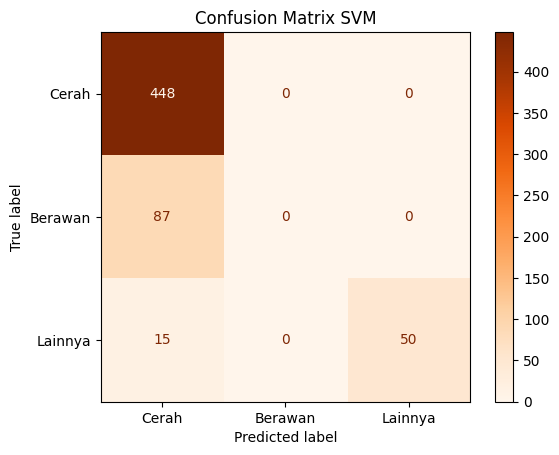

In [9]:
# SVM_soft_margin cuma bisa 2 kelas (-1/1), jadi dipakai cara One-vs-Rest:
# dibuat 3 SVM (cerah vs bukan, berawan vs bukan, lainnya vs bukan),
# lalu prediksinya diambil dari kelas dengan skor tertinggi
class SVM_multiclass:
    def __init__(self, alpha=0.001, lambda_=0.01, n_iterations=100):
        self.alpha = alpha
        self.lambda_ = lambda_
        self.n_iterations = n_iterations
        self.models = {}

    def fit(self, X, y):
        self.kelas = np.unique(y)
        for c in self.kelas:
            y_biner = np.where(y == c, 1, -1)
            svm = SVM_soft_margin(self.alpha, self.lambda_, self.n_iterations)
            svm.fit(X, y_biner)
            self.models[c] = svm
        return self

    def predict(self, X):
        skor = np.array([np.dot(X, self.models[c].w) - self.models[c].b for c in self.kelas])
        return self.kelas[np.argmax(skor, axis=0)]

svm_cuaca = SVM_multiclass(alpha=0.001, lambda_=0.01, n_iterations=100)
svm_cuaca.fit(X_train_s, y_train)
y_pred_svm = svm_cuaca.predict(X_test_s)

print('=== SVM ===')
print(classification_report(y_test, y_pred_svm, target_names=nama_kelas, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_svm), display_labels=nama_kelas).plot(cmap='Oranges')
plt.title('Confusion Matrix SVM')
plt.show()

In [10]:
hasil = pd.DataFrame({
    'Model': ['kNN', 'SVM soft margin (OvR)'],
    'Accuracy': [accuracy_score(y_test, y_pred_knn), accuracy_score(y_test, y_pred_svm)],
    'Precision (macro)': [precision_score(y_test, y_pred_knn, average='macro', zero_division=0),
                          precision_score(y_test, y_pred_svm, average='macro', zero_division=0)],
    'Recall (macro)': [recall_score(y_test, y_pred_knn, average='macro', zero_division=0),
                       recall_score(y_test, y_pred_svm, average='macro', zero_division=0)],
    'F1 (macro)': [f1_score(y_test, y_pred_knn, average='macro', zero_division=0),
                   f1_score(y_test, y_pred_svm, average='macro', zero_division=0)],
})
hasil.round(3)

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,kNN,0.848,0.843,0.654,0.709
1,SVM soft margin (OvR),0.830,0.605,0.590,0.589
